# Импорт данных CIFAR-10

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = "./data"

def unpickle(file):
    import pickle
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

Тренировочные данные

In [3]:
train_batches = []
for i in range(1, 6):
    train_batches.append(unpickle(Path(DATA_DIR) / f"cifar-10-batches-py/data_batch_{i}"))

X_train = np.concatenate([b[b'data'] for b in train_batches], axis=0)
X_train = X_train.reshape(len(X_train), 3, 32, 32).astype(np.float32) / 255.0
Y_train = np.concatenate([b[b'labels'] for b in train_batches], axis=0)

Тестовые данные

In [4]:
test_batch = unpickle(Path(DATA_DIR) / "cifar-10-batches-py/test_batch")

X_test = test_batch[b'data'].reshape(len(test_batch[b'data']), 3, 32, 32).astype(np.float32) / 255.0
Y_test = test_batch[b'labels']

Метки

In [5]:
label_names = unpickle(Path(DATA_DIR) / "cifar-10-batches-py/batches.meta")[b'label_names']
label_names = [name.decode('utf-8') for name in label_names]
label_names

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

# Вывод данных

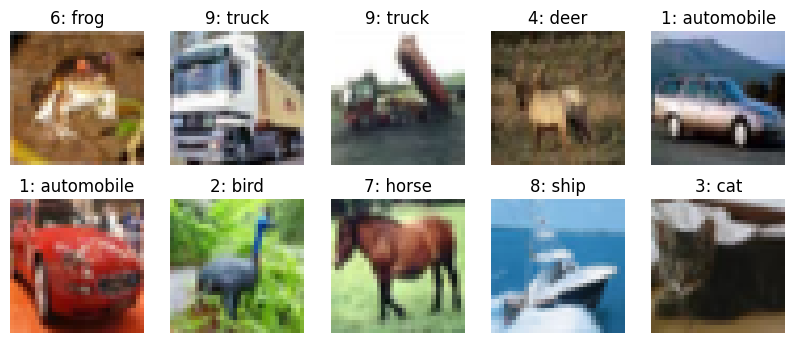

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].transpose(1, 2, 0))
    ax.set_title(f"{Y_train[i]}: {label_names[Y_train[i]]}")
    ax.axis('off')

# Предподготовка данных

In [ ]:
mean = X_train.mean(axis=(0, 2, 3), keepdims=True)
std = X_train.std(axis=(0, 2, 3), keepdims=True)

print("mean:", mean.flatten())
print("std: ", std.flatten())

X_train_norm = (X_train - mean) / std
X_test_norm = (X_test - mean) / std

print(X_train_norm.mean(axis=(0, 2, 3)), X_train_norm.std(axis=(0, 2, 3)))

mean: [0.4914009  0.48215896 0.4465308 ]
std:  [0.24703279 0.24348423 0.26158753]
[-4.9009900e-06 -2.2219915e-06  5.1376878e-07] [0.99999595 1.0000024  1.0000004 ]


# Создание модели

In [10]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super().__init__()

        self.kernel_size = 3
        self.stride = stride
        self.padding = 1

        self.conv1 = nn.Conv2d(in_channels, out_channels, self.kernel_size, stride, self.padding, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu1 = nn.ReLU()
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, self.kernel_size, 1, self.padding, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Sequential(nn.Conv2d(in_channels, out_channels, 1, stride, bias=False), nn.BatchNorm2d(out_channels)) if self.stride != 1 or in_channels != out_channels else nn.Sequential()

        self.relu2 = nn.ReLU()

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu1(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + self.shortcut(x)

        out = self.relu2(out)

        return out


class MyResNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size = 3, stride = 1, padding = 1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu1 = nn.ReLU()

        self.redidualBlock1 = ResidualBlock(in_channels=16, out_channels=16, stride=1)
        self.redidualBlock2 = ResidualBlock(in_channels=16, out_channels=16, stride=1)
        self.redidualBlock3 = ResidualBlock(in_channels=16, out_channels=16, stride=1)

        self.redidualBlock4 = ResidualBlock(in_channels=16, out_channels=32, stride=2)
        self.redidualBlock5 = ResidualBlock(in_channels=32, out_channels=32, stride=1)
        self.redidualBlock6 = ResidualBlock(in_channels=32, out_channels=32, stride=1)

        self.redidualBlock7 = ResidualBlock(in_channels=32, out_channels=64, stride=2)
        self.redidualBlock8 = ResidualBlock(in_channels=64, out_channels=64, stride=1)
        self.redidualBlock9 = ResidualBlock(in_channels=64, out_channels=64, stride=1)


        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.linear = nn.Linear(64, 10)


    def forward(self, batch):
        x = self.conv1(batch)
        x = self.bn1(x)
        x = self.relu1(x)

        x = self.redidualBlock1(x)
        x = self.redidualBlock2(x)
        x = self.redidualBlock3(x)

        x = self.redidualBlock4(x)
        x = self.redidualBlock5(x)
        x = self.redidualBlock6(x)

        x = self.redidualBlock7(x)
        x = self.redidualBlock8(x)
        x = self.redidualBlock9(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1) 
        x = self.linear(x)

        return x


In [ ]:
import torch
import torch.nn.functional as F

def random_crop(img, padding=4):
    _, h, w = img.shape
    padded = F.pad(img, (padding, padding, padding, padding))

    top = torch.randint(0, 2 * padding + 1, (1,)).item()
    left = torch.randint(0, 2 * padding + 1, (1,)).item()
    return padded[:, top:top + h, left:left + w]

def random_horizontal_flip(img, p=0.5):
    if torch.rand(1).item() < p:
        return img.flip(-1)
    return img

In [ ]:
from torch.utils.data import Dataset, DataLoader

class CIFARDataset(Dataset):
    def __init__(self, images, labels, augment=False):
        self.images = torch.from_numpy(images)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.augment:
            img = random_crop(img, padding=4)
            img = random_horizontal_flip(img)
        return img, self.labels[idx]


train_dataset = CIFARDataset(X_train_norm, Y_train, augment=False)
test_dataset = CIFARDataset(X_test_norm, Y_test, augment=False)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# Обучение модели

In [13]:
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

model = MyResNet().to(device)

num_epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9,
                            weight_decay=5e-4, nesterov=True)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

Устройство: cuda


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

In [ ]:
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs + 1):
    start = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)  
    history["test_acc"].append(test_acc)

    print(f"Эпоха {epoch:2d}/{num_epochs} | "
          f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
          f"test loss {test_loss:.4f}, acc {test_acc:.4f} | "
          f"lr {scheduler.get_last_lr()[0]:.4f} | {time.time() - start:.1f} с")

torch.save(model.state_dict(), "resnet20_cifar10.pth")

Эпоха  1/30 | train loss 1.4733, acc 0.4519 | test loss 1.2954, acc 0.5405 | lr 0.0997 | 24.2 с
Эпоха  2/30 | train loss 0.9475, acc 0.6623 | test loss 1.0047, acc 0.6533 | lr 0.0989 | 24.8 с
Эпоха  3/30 | train loss 0.7351, acc 0.7425 | test loss 0.7869, acc 0.7292 | lr 0.0976 | 24.6 с
Эпоха  4/30 | train loss 0.6362, acc 0.7785 | test loss 0.8195, acc 0.7286 | lr 0.0957 | 25.7 с
Эпоха  5/30 | train loss 0.5710, acc 0.8012 | test loss 0.7441, acc 0.7446 | lr 0.0933 | 22.6 с
Эпоха  6/30 | train loss 0.5241, acc 0.8197 | test loss 0.7146, acc 0.7548 | lr 0.0905 | 22.6 с
Эпоха  7/30 | train loss 0.4885, acc 0.8308 | test loss 0.7279, acc 0.7554 | lr 0.0872 | 23.3 с
Эпоха  8/30 | train loss 0.4611, acc 0.8396 | test loss 0.8766, acc 0.7275 | lr 0.0835 | 22.6 с
Эпоха  9/30 | train loss 0.4359, acc 0.8489 | test loss 0.7429, acc 0.7525 | lr 0.0794 | 21.5 с
Эпоха 10/30 | train loss 0.4092, acc 0.8577 | test loss 0.7143, acc 0.7503 | lr 0.0750 | 21.5 с
Эпоха 11/30 | train loss 0.3830, acc 0.8

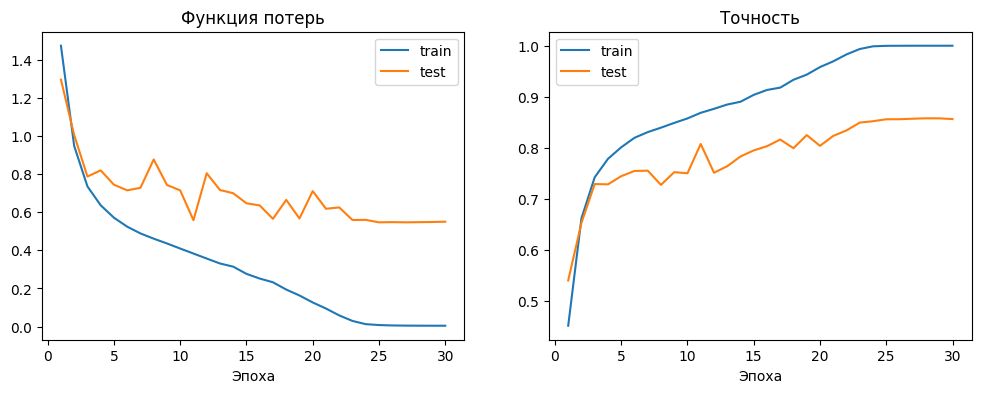

In [16]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["test_loss"], label="test")
ax1.set_title("Функция потерь"); ax1.set_xlabel("Эпоха"); ax1.legend()

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["test_acc"], label="test")
ax2.set_title("Точность"); ax2.set_xlabel("Эпоха"); ax2.legend()
plt.show()

# Тестрирование модели

In [17]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Итоговая точность на тесте: {test_acc:.4f}")

@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        outputs = model(images.to(device))
        all_preds.append(outputs.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

preds, true_labels = predict(model, test_loader, device)

for c, name in enumerate(label_names):
    mask = true_labels == c
    class_acc = (preds[mask] == c).mean()
    print(f"{name:>10s}: {class_acc:.4f}")

Итоговая точность на тесте: 0.8564
  airplane: 0.8780
automobile: 0.9330
      bird: 0.8000
       cat: 0.7090
      deer: 0.8400
       dog: 0.8010
      frog: 0.8960
     horse: 0.8800
      ship: 0.9200
     truck: 0.9070


# Обучение с аугментацией данных

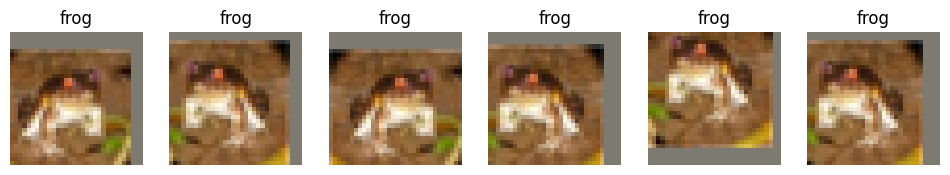

In [18]:
train_dataset_aug = CIFARDataset(X_train_norm, Y_train, augment=True)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=128, shuffle=True)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax in axes:
    img, label = train_dataset_aug[0]
    img = img.numpy() * std[0] + mean[0]
    ax.imshow(img.transpose(1, 2, 0).clip(0, 1))
    ax.set_title(label_names[label.item()])
    ax.axis('off')
plt.show()

In [19]:
model_aug = MyResNet().to(device)
optimizer_aug = torch.optim.SGD(model_aug.parameters(), lr=0.1, momentum=0.9,
                                weight_decay=5e-4, nesterov=True)
scheduler_aug = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_aug, T_max=num_epochs)

history_aug = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs + 1):
    start = time.time()

    train_loss, train_acc = train_one_epoch(model_aug, train_loader_aug, criterion, optimizer_aug, device)
    test_loss, test_acc = evaluate(model_aug, test_loader, criterion, device)
    scheduler_aug.step()

    history_aug["train_loss"].append(train_loss)
    history_aug["train_acc"].append(train_acc)
    history_aug["test_loss"].append(test_loss)
    history_aug["test_acc"].append(test_acc)

    print(f"Эпоха {epoch:2d}/{num_epochs} | "
          f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
          f"test loss {test_loss:.4f}, acc {test_acc:.4f} | "
          f"lr {scheduler_aug.get_last_lr()[0]:.4f} | {time.time() - start:.1f} с")

torch.save(model_aug.state_dict(), "resnet20_cifar10_aug.pth")

Эпоха  1/30 | train loss 1.5512, acc 0.4258 | test loss 1.3953, acc 0.5221 | lr 0.0997 | 28.8 с
Эпоха  2/30 | train loss 1.0549, acc 0.6211 | test loss 1.5011, acc 0.5551 | lr 0.0989 | 28.0 с
Эпоха  3/30 | train loss 0.8342, acc 0.7058 | test loss 1.0704, acc 0.6383 | lr 0.0976 | 29.7 с
Эпоха  4/30 | train loss 0.7263, acc 0.7483 | test loss 0.9053, acc 0.7005 | lr 0.0957 | 29.1 с
Эпоха  5/30 | train loss 0.6608, acc 0.7720 | test loss 0.8189, acc 0.7326 | lr 0.0933 | 32.0 с
Эпоха  6/30 | train loss 0.6190, acc 0.7864 | test loss 0.7547, acc 0.7451 | lr 0.0905 | 33.6 с
Эпоха  7/30 | train loss 0.5855, acc 0.7980 | test loss 0.7695, acc 0.7448 | lr 0.0872 | 31.7 с
Эпоха  8/30 | train loss 0.5618, acc 0.8087 | test loss 0.6837, acc 0.7701 | lr 0.0835 | 33.8 с
Эпоха  9/30 | train loss 0.5392, acc 0.8133 | test loss 0.6329, acc 0.7867 | lr 0.0794 | 28.3 с
Эпоха 10/30 | train loss 0.5151, acc 0.8230 | test loss 0.9842, acc 0.7002 | lr 0.0750 | 29.4 с
Эпоха 11/30 | train loss 0.4952, acc 0.8

# Сравнение моделей: без аугментации и с аугментацией

In [20]:
_, train_acc_base = evaluate(model, train_loader, criterion, device)
_, test_acc_base = evaluate(model, test_loader, criterion, device)
_, train_acc_aug = evaluate(model_aug, train_loader, criterion, device)
_, test_acc_aug = evaluate(model_aug, test_loader, criterion, device)

print(f"{'':>20s} {'train':>8s} {'test':>8s} {'разрыв':>8s}")
print(f"{'Без аугментации':>20s} {train_acc_base:8.4f} {test_acc_base:8.4f} {train_acc_base - test_acc_base:8.4f}")
print(f"{'С аугментацией':>20s} {train_acc_aug:8.4f} {test_acc_aug:8.4f} {train_acc_aug - test_acc_aug:8.4f}")
print()

preds_base, true_labels = predict(model, test_loader, device)
preds_aug, _ = predict(model_aug, test_loader, device)

print(f"{'класс':>10s} {'без аугм.':>10s} {'с аугм.':>10s} {'разница':>10s}")
for c, name in enumerate(label_names):
    mask = true_labels == c
    acc_base = (preds_base[mask] == c).mean()
    acc_aug = (preds_aug[mask] == c).mean()
    print(f"{name:>10s} {acc_base:10.4f} {acc_aug:10.4f} {acc_aug - acc_base:+10.4f}")

                        train     test   разрыв
     Без аугментации   1.0000   0.8564   0.1436
      С аугментацией   0.9642   0.9051   0.0591

     класс  без аугм.    с аугм.    разница
  airplane     0.8780     0.9140    +0.0360
automobile     0.9330     0.9580    +0.0250
      bird     0.8000     0.8730    +0.0730
       cat     0.7090     0.7750    +0.0660
      deer     0.8400     0.9270    +0.0870
       dog     0.8010     0.8540    +0.0530
      frog     0.8960     0.9400    +0.0440
     horse     0.8800     0.9290    +0.0490
      ship     0.9200     0.9470    +0.0270
     truck     0.9070     0.9340    +0.0270


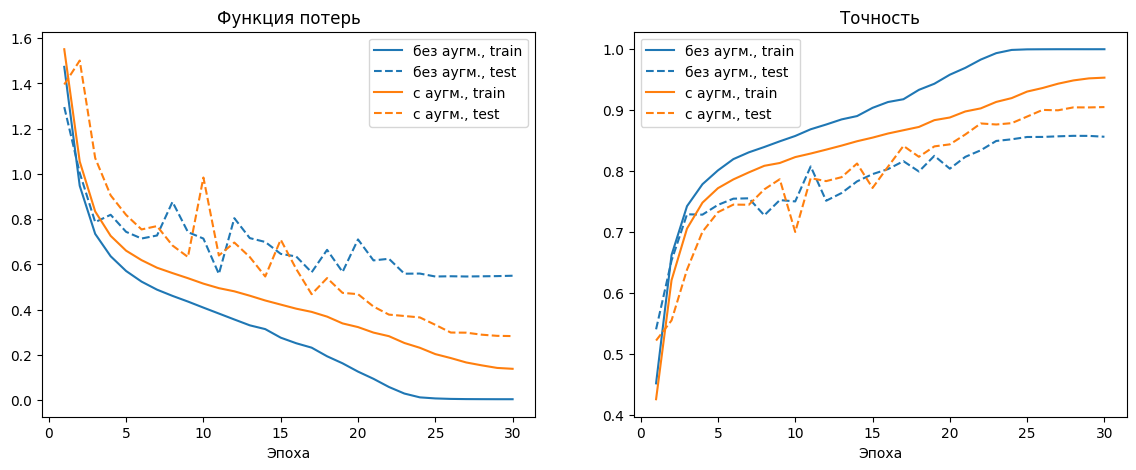

In [21]:
epochs = range(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs, history["train_loss"], color="tab:blue", label="без аугм., train")
ax1.plot(epochs, history["test_loss"], color="tab:blue", linestyle="--", label="без аугм., test")
ax1.plot(epochs, history_aug["train_loss"], color="tab:orange", label="с аугм., train")
ax1.plot(epochs, history_aug["test_loss"], color="tab:orange", linestyle="--", label="с аугм., test")
ax1.set_title("Функция потерь"); ax1.set_xlabel("Эпоха"); ax1.legend()

ax2.plot(epochs, history["train_acc"], color="tab:blue", label="без аугм., train")
ax2.plot(epochs, history["test_acc"], color="tab:blue", linestyle="--", label="без аугм., test")
ax2.plot(epochs, history_aug["train_acc"], color="tab:orange", label="с аугм., train")
ax2.plot(epochs, history_aug["test_acc"], color="tab:orange", linestyle="--", label="с аугм., test")
ax2.set_title("Точность"); ax2.set_xlabel("Эпоха"); ax2.legend()
plt.show()